# Can the EVK4 detect the line-laser modulation?

**Goal.** We want depth from two rectified EVK4 cameras that watch a line laser being scanned by a stepper motor.
The laser is modulated (50 % duty cycle) at **100 kHz** or **200 kHz**, and the motor dwells **10, 50, 100 or
200 µs** on each step (about 20 µs nominal step time). The first question is whether the cameras can detect the
modulation frequency at all.

**Data.** Two sets of recordings from `04_dual_cam_recorder` (hardware-synchronised, one HDF5 file per camera):

| Folder | Sensor filters |
|---|---|
| `recordings/step_time_10us_with_trail_filter` | trail filter ON (100 ms), ERC off |
| `recordings/step_time_10us` | trail filter OFF, ERC off |

Each folder holds the 8 combinations `<frequency>_<dwell>` for the left (00050496) and right (00051788) cameras.

**Approach.**
1. Data overview and the right camera's noise (hot pixels).
2. Scan structure: laser sweeps and the measured motor step period.
3. **Per pixel**: intervals between consecutive events of one pixel. Can a pixel fire fast enough to follow the carrier?
4. **Positive control**: the motor steps lock the event timing. The step harmonics measure up to which frequency
   event timestamps still carry phase information ("temporal transfer").
5. **Population search for the carrier**: per sweep, ON/OFF event counts in 1 µs bins → FFT, normalised so that
   unlocked events give Exp(1) power per bin. Summed over S sweeps the noise is Gamma(S, 1). A carrier that
   phase-locks a fraction of the events shows up as an excess at f_mod (equivalent to a Rayleigh test of the event
   phases). A ±2 kHz window absorbs any clock mismatch between the signal generator and the camera.
6. **Sensitivity**: synthetic phase-locked events injected into real data tell how small a locked fraction would
   still be detected.

The heavy lifting is in `modulation_analysis.py`. Per-file results are cached in `cache/`, so the notebook
re-runs in seconds. Set `USE_CACHE = False` to recompute from the HDF5 files (about 5 minutes).

In [1]:
%matplotlib inline
import pickle
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import modulation_analysis as ma

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
USE_CACHE = True  # False: recompute everything from the HDF5 files

recs = ma.list_recordings()
results = {r: ma.analyze_recording(r, use_cache=USE_CACHE) for r in recs}
print(f"{len(results)} camera files analysed")

OFF, TRAIL = "filters OFF", "trail filter ON"
DWELLS = sorted({r.dwell_us for r in recs})
FREQS = sorted({r.fmod_hz for r in recs})
DWELL_COLORS = dict(zip(DWELLS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]))
CAM_COLORS = {"left": "#1f77b4", "right": "#d62728"}


def md_table(header, rows):
    out = "| " + " | ".join(header) + " |\n|" + "---|" * len(header) + "\n"
    out += "\n".join("| " + " | ".join(str(c) for c in row) + " |" for row in rows)
    display(Markdown(out))


def get(folder, fmod, dwell, role):
    return results[next(r for r in recs if r.folder == folder and r.fmod_hz == fmod and r.dwell_us == dwell
                        and r.role == role)]


def fmt_p(lp):
    return "1" if lp > -0.05 else f"1e{lp:.1f}"

32 camera files analysed


## 1. Data overview

*Hot px*: pixels averaging > 1000 ev/s (normal pixels average < 10 ev/s), with their share of all events. They are
removed for every analysis below. *Sweeps*: periods where the event rate rises above the background (laser scanning
through the field of view).

In [2]:
rows = []
for r in recs:
    res = results[r]
    hot_share = 1 - res["n_clean"] / res["n_raw"]
    rows.append([r.folder, r.name, r.role, f"{res['duration_s']:.2f}", f"{res['n_raw'] / res['duration_s'] / 1e6:.2f}",
                 f"{len(res['hot'])} ({hot_share * 100:.1f} %)", f"{res['n_clean'] / res['duration_s'] / 1e6:.2f}",
                 f"{res['on_fraction'] * 100:.0f} %", res.get("n_sweeps", 0), f"{res.get('sweep_len_ms', 0):.0f}"])
md_table(["Folder", "Combination", "Camera", "Duration (s)", "Raw rate (Mev/s)", "Hot px (share)",
          "Clean rate (Mev/s)", "ON", "Sweeps", "Median sweep (ms)"], rows)

| Folder | Combination | Camera | Duration (s) | Raw rate (Mev/s) | Hot px (share) | Clean rate (Mev/s) | ON | Sweeps | Median sweep (ms) |
|---|---|---|---|---|---|---|---|---|---|
| trail filter ON | 100kHz_10us | left | 5.72 | 0.06 | 0 (0.0 %) | 0.06 | 44 % | 5 | 29 |
| trail filter ON | 100kHz_10us | right | 5.72 | 0.09 | 0 (0.0 %) | 0.09 | 37 % | 5 | 30 |
| trail filter ON | 100kHz_50us | left | 5.94 | 0.76 | 0 (0.0 %) | 0.76 | 49 % | 12 | 97 |
| trail filter ON | 100kHz_50us | right | 5.94 | 0.47 | 0 (0.0 %) | 0.47 | 45 % | 12 | 89 |
| trail filter ON | 100kHz_100us | left | 6.74 | 1.41 | 0 (0.0 %) | 1.41 | 44 % | 6 | 280 |
| trail filter ON | 100kHz_100us | right | 6.74 | 1.04 | 0 (0.0 %) | 1.04 | 43 % | 6 | 257 |
| trail filter ON | 100kHz_200us | left | 7.38 | 1.66 | 0 (0.0 %) | 1.66 | 39 % | 9 | 235 |
| trail filter ON | 100kHz_200us | right | 7.38 | 1.55 | 0 (0.0 %) | 1.55 | 40 % | 6 | 318 |
| trail filter ON | 200kHz_10us | left | 5.70 | 0.06 | 0 (0.0 %) | 0.06 | 43 % | 5 | 29 |
| trail filter ON | 200kHz_10us | right | 5.70 | 0.10 | 0 (0.0 %) | 0.10 | 37 % | 5 | 24 |
| trail filter ON | 200kHz_50us | left | 6.44 | 0.74 | 0 (0.0 %) | 0.74 | 46 % | 9 | 170 |
| trail filter ON | 200kHz_50us | right | 6.44 | 0.46 | 0 (0.0 %) | 0.46 | 42 % | 7 | 226 |
| trail filter ON | 200kHz_100us | left | 6.72 | 1.49 | 0 (0.0 %) | 1.49 | 43 % | 6 | 276 |
| trail filter ON | 200kHz_100us | right | 6.72 | 1.14 | 0 (0.0 %) | 1.14 | 43 % | 6 | 259 |
| trail filter ON | 200kHz_200us | left | 9.82 | 1.69 | 0 (0.0 %) | 1.69 | 39 % | 11 | 216 |
| trail filter ON | 200kHz_200us | right | 9.82 | 1.61 | 0 (0.0 %) | 1.61 | 40 % | 8 | 319 |
| filters OFF | 100kHz_10us | left | 6.24 | 0.06 | 0 (0.0 %) | 0.06 | 47 % | 6 | 30 |
| filters OFF | 100kHz_10us | right | 6.24 | 9.09 | 2 (98.9 %) | 0.10 | 39 % | 6 | 27 |
| filters OFF | 100kHz_50us | left | 6.50 | 0.75 | 0 (0.0 %) | 0.75 | 49 % | 10 | 166 |
| filters OFF | 100kHz_50us | right | 6.50 | 9.10 | 2 (94.9 %) | 0.46 | 44 % | 7 | 210 |
| filters OFF | 100kHz_100us | left | 6.74 | 1.02 | 0 (0.0 %) | 1.02 | 38 % | 12 | 105 |
| filters OFF | 100kHz_100us | right | 6.74 | 9.16 | 3 (87.1 %) | 1.19 | 44 % | 6 | 269 |
| filters OFF | 100kHz_200us | left | 7.86 | 1.26 | 0 (0.0 %) | 1.26 | 36 % | 15 | 59 |
| filters OFF | 100kHz_200us | right | 7.86 | 9.59 | 2 (76.8 %) | 2.22 | 44 % | 6 | 344 |
| filters OFF | 200kHz_10us | left | 6.50 | 0.09 | 0 (0.0 %) | 0.09 | 42 % | 6 | 32 |
| filters OFF | 200kHz_10us | right | 6.50 | 9.09 | 2 (98.3 %) | 0.15 | 38 % | 6 | 26 |
| filters OFF | 200kHz_50us | left | 6.76 | 0.89 | 0 (0.0 %) | 0.89 | 49 % | 6 | 260 |
| filters OFF | 200kHz_50us | right | 6.76 | 9.12 | 3 (94.3 %) | 0.52 | 44 % | 6 | 236 |
| filters OFF | 200kHz_100us | left | 7.48 | 1.06 | 0 (0.0 %) | 1.06 | 37 % | 14 | 62 |
| filters OFF | 200kHz_100us | right | 7.48 | 9.19 | 2 (85.1 %) | 1.37 | 45 % | 7 | 276 |
| filters OFF | 200kHz_200us | left | 7.28 | 0.99 | 0 (0.0 %) | 0.99 | 41 % | 13 | 55 |
| filters OFF | 200kHz_200us | right | 7.28 | 9.68 | 2 (76.5 %) | 2.27 | 42 % | 6 | 324 |

## 2. The right camera's noise is a few hot pixels

With the filters off, the right camera's ~9 Mev/s baseline comes almost entirely from **2–3 pixels**, each firing
millions of OFF events per second. The trail filter hides them because they emit long bursts of one polarity. That
is why the filtered recordings look clean, but the same filter also removes the fast repetitions we want to study
(section 4).

| Pixel (x, y) | Files where hot | Mean rate (Mev/s) | ON fraction | Cameras |
|---|---|---|---|---|
| (407, 685) | 8 / 8 | 4.09 | 0.000 | right |
| (763, 371) | 8 / 8 | 4.10 | 0.000 | right |
| (48, 212) | 2 / 8 | 0.10 | 0.000 | right |

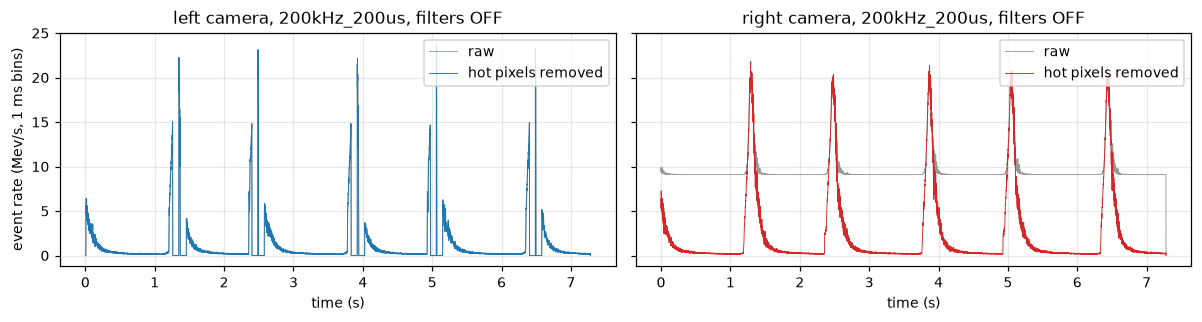

In [3]:
hot_px = {}
for r in recs:
    if r.folder != OFF:
        continue
    for h in results[r]["hot"]:
        d = hot_px.setdefault((h["x"], h["y"]), dict(rates=[], on=[], files=[]))
        d["rates"].append(h["rate_evs"]); d["on"].append(h["on_fraction"]); d["files"].append(f"{r.name}/{r.role}")
md_table(["Pixel (x, y)", "Files where hot", "Mean rate (Mev/s)", "ON fraction", "Cameras"],
         [[f"({x}, {y})", f"{len(d['files'])} / 8", f"{np.mean(d['rates']) / 1e6:.2f}", f"{np.mean(d['on']):.3f}",
           ", ".join(sorted({f.split('/')[1] for f in d['files']}))]
          for (x, y), d in sorted(hot_px.items(), key=lambda kv: -len(kv[1]["files"]))])

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, role in zip(axes, ("left", "right")):
    res = get(OFF, 200e3, 200, role)
    ax.plot(res["rate_t"], res["rate_raw"] / 1e6, lw=0.6, color="0.6", label="raw")
    ax.plot(res["rate_t"], res["rate_clean"] / 1e6, lw=0.6, color=CAM_COLORS[role], label="hot pixels removed")
    ax.set_title(f"{role} camera, 200kHz_200us, filters OFF"); ax.set_xlabel("time (s)")
    ax.legend(loc="upper right")
axes[0].set_ylabel("event rate (Mev/s, 1 ms bins)")
plt.tight_layout(); plt.show()

### Data integrity: gaps in the event stream

A gap is flagged when no event arrives for > 2 ms while the stream is busy (the 2000 events before and after the
gap each span < 1 ms), which indicates lost data rather than a quiet scene.

| Folder | Combination | Camera | Peak rate (Mev/s, 1 ms) | Gaps | Lost time (ms) | Median gap (ms) |
|---|---|---|---|---|---|---|
| trail filter ON | 100kHz_10us | left | 1.2 | 0 | 0 | – |
| trail filter ON | 100kHz_10us | right | 0.8 | 0 | 0 | – |
| trail filter ON | 100kHz_50us | left | 12.2 | 0 | 0 | – |
| trail filter ON | 100kHz_50us | right | 8.0 | 0 | 0 | – |
| trail filter ON | 100kHz_100us | left | 11.1 | 0 | 0 | – |
| trail filter ON | 100kHz_100us | right | 9.4 | 0 | 0 | – |
| trail filter ON | 100kHz_200us | left | 13.9 | 0 | 0 | – |
| trail filter ON | 100kHz_200us | right | 12.0 | 0 | 0 | – |
| trail filter ON | 200kHz_10us | left | 0.7 | 0 | 0 | – |
| trail filter ON | 200kHz_10us | right | 0.5 | 0 | 0 | – |
| trail filter ON | 200kHz_50us | left | 12.6 | 0 | 0 | – |
| trail filter ON | 200kHz_50us | right | 9.3 | 0 | 0 | – |
| trail filter ON | 200kHz_100us | left | 12.5 | 0 | 0 | – |
| trail filter ON | 200kHz_100us | right | 9.7 | 0 | 0 | – |
| trail filter ON | 200kHz_200us | left | 14.8 | 0 | 0 | – |
| trail filter ON | 200kHz_200us | right | 12.7 | 0 | 0 | – |
| filters OFF | 100kHz_10us | left | 1.3 | 0 | 0 | – |
| filters OFF | 100kHz_10us | right | 9.1 | 0 | 0 | – |
| filters OFF | 100kHz_50us | left | 12.7 | 0 | 0 | – |
| filters OFF | 100kHz_50us | right | 9.9 | 0 | 0 | – |
| filters OFF | 100kHz_100us | left | 14.7 | 5 | 434 | 86.7 |
| filters OFF | 100kHz_100us | right | 11.4 | 0 | 0 | – |
| filters OFF | 100kHz_200us | left | 21.6 | 9 | 780 | 86.4 |
| filters OFF | 100kHz_200us | right | 18.9 | 0 | 0 | – |
| filters OFF | 200kHz_10us | left | 1.0 | 0 | 0 | – |
| filters OFF | 200kHz_10us | right | 9.1 | 0 | 0 | – |
| filters OFF | 200kHz_50us | left | 13.9 | 0 | 0 | – |
| filters OFF | 200kHz_50us | right | 10.0 | 0 | 0 | – |
| filters OFF | 200kHz_100us | left | 15.6 | 5 | 439 | 87.9 |
| filters OFF | 200kHz_100us | right | 12.4 | 0 | 0 | – |
| filters OFF | 200kHz_200us | left | 23.8 | 10 | 874 | 86.7 |
| filters OFF | 200kHz_200us | right | 21.8 | 0 | 0 | – |

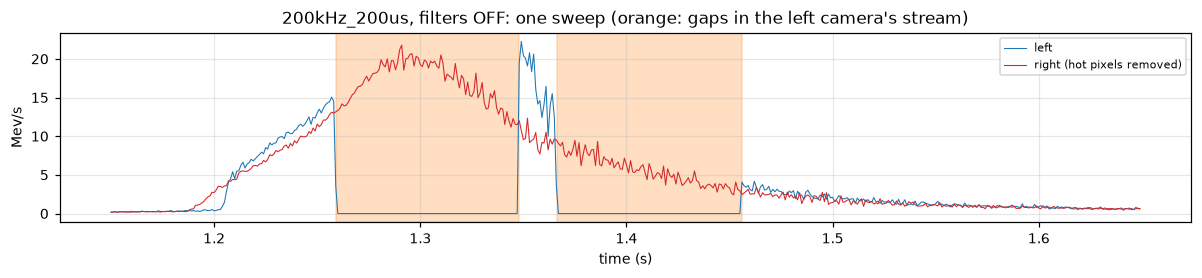

In [4]:
rows = []
for r in recs:
    res = results[r]
    g = res["gaps"]
    rows.append([r.folder, r.name, r.role, f"{res['peak_rate_mevs']:.1f}", len(g),
                 f"{sum(x[1] for x in g) / 1e3:.0f}", f"{np.median([x[1] for x in g]) / 1e3:.1f}" if g else "–"])
md_table(["Folder", "Combination", "Camera", "Peak rate (Mev/s, 1 ms)", "Gaps", "Lost time (ms)", "Median gap (ms)"],
         rows)

fig, ax = plt.subplots(figsize=(11, 2.6))
res = get(OFF, 200e3, 200, "left")
i0, i1 = 1150, 1650
ax.plot(res["rate_t"][i0:i1], res["rate_raw"][i0:i1] / 1e6, lw=0.7, color=CAM_COLORS["left"], label="left")
ax.plot(res["rate_t"][i0:i1], get(OFF, 200e3, 200, "right")["rate_clean"][i0:i1] / 1e6, lw=0.7,
        color=CAM_COLORS["right"], label="right (hot pixels removed)")
for t0, g in res["gaps"]:
    if res["rate_t"][i0] <= t0 * 1e-6 <= res["rate_t"][i1]:
        ax.axvspan(t0 * 1e-6, (t0 + g) * 1e-6, color="tab:orange", alpha=0.25)
ax.set_xlabel("time (s)"); ax.set_ylabel("Mev/s"); ax.legend(fontsize=7)
ax.set_title("200kHz_200us, filters OFF: one sweep (orange: gaps in the left camera's stream)")
plt.tight_layout(); plt.show()

With the filters off, the **left camera (00050496, sync master) loses about 86–88 ms of data at a time** at the
peak of the 100 µs and 200 µs sweeps, as soon as its rate passes about 15 Mev/s: 5–10 gaps and 0.4–0.9 s lost per
recording. The right camera passes ~22 Mev/s of scene events, ~30 Mev/s including its hot pixels, without a
single gap. So this is not a bandwidth limit shared by both cameras. It is specific to the left camera, its USB
port/controller, or its master role. The recorder never drops events (its queue is unbounded), so the loss happens
before the data reaches the application. The gaps do not
affect the modulation analysis, which only uses the data that exists, but they matter for depth estimation.
The sweep detection splits sweeps at these gaps, which is why the left camera often has more, shorter sweeps.

## 3. Scan structure and motor timing

Each sweep is the laser line crossing the field of view. The motor step period is measured from the strongest
spectral line in the expected range (period = dwell + 15…80 µs), refined per sweep.

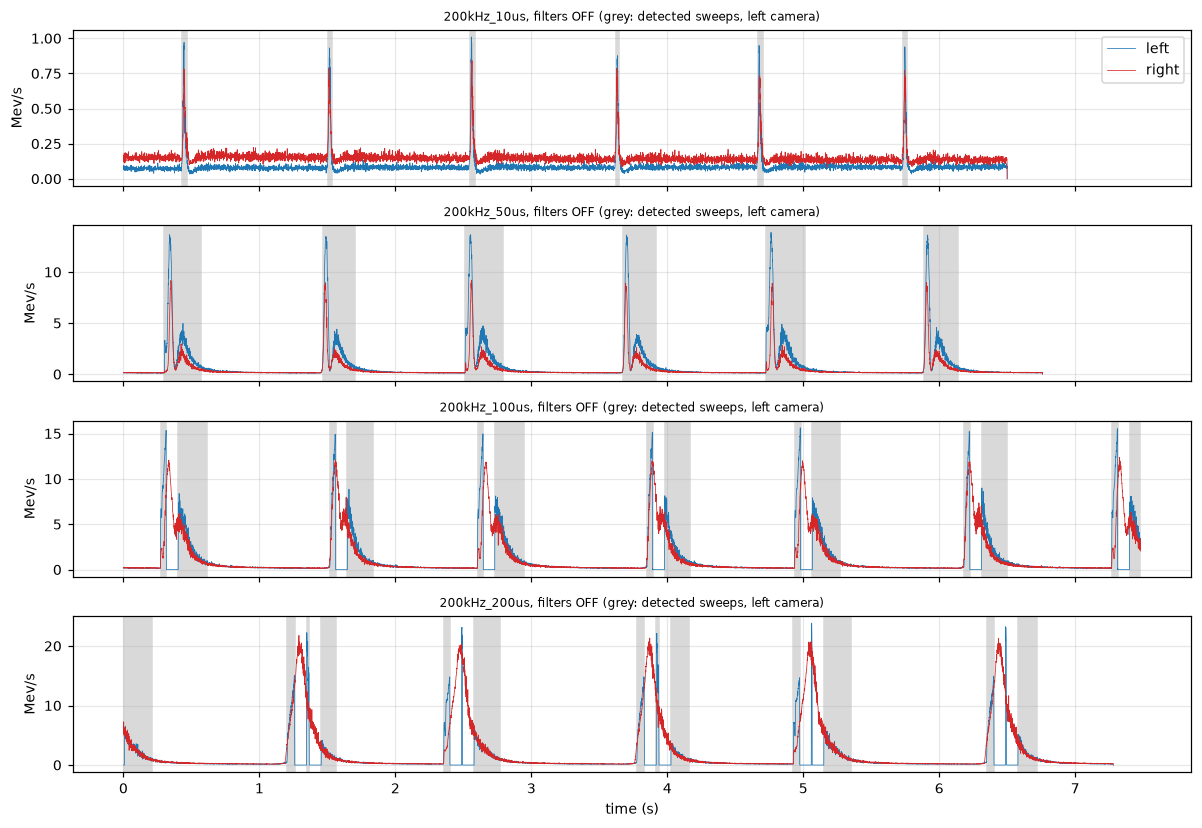

| Dwell (µs) | Files with step detected (of 8) | Step period (µs) | Overhead (µs) | 500-step scan | Line positions per 100 ms (10 fps) | Events per step L / R (filters OFF) |
|---|---|---|---|---|---|---|
| 10 | 3 | 49.98 | 40.0 | 25 ms (40 fps) | 2001 | 25 / 22 |
| 50 | 8 | 88.61 | 38.6 | 44 ms (23 fps) | 1129 | 263 / 146 |
| 100 | 8 | 138.63 | 38.6 | 69 ms (14 fps) | 721 | 580 / 596 |
| 200 | 8 | 238.90 | 38.9 | 119 ms (8 fps) | 419 | 1113 / 1826 |

In [5]:
fig, axes = plt.subplots(len(DWELLS), 1, figsize=(11, 1.9 * len(DWELLS)), sharex=True)
for ax, dwell in zip(axes, DWELLS):
    for role in ("left", "right"):
        res = get(OFF, 200e3, dwell, role)
        ax.plot(res["rate_t"], res["rate_clean"] / 1e6, lw=0.5, color=CAM_COLORS[role], label=role)
    for s, e in get(OFF, 200e3, dwell, "left")["sweeps"]:
        ax.axvspan(s * 1e-6, e * 1e-6, color="0.85", zorder=0)
    ax.set_ylabel("Mev/s"); ax.set_title(f"200kHz_{dwell}us, filters OFF (grey: detected sweeps, left camera)",
                                        fontsize=8)
axes[0].legend(loc="upper right"); axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

rows = []
for dwell in DWELLS:
    sel = [results[r] for r in recs if r.dwell_us == dwell and results[r].get("step_detected")]
    per = np.array([np.mean(1e6 / s["f_step"]) for s in sel])
    eps = {role: np.median([results[r]["events_per_step"] for r in recs
                            if r.dwell_us == dwell and r.role == role and r.folder == OFF]) for role in ("left", "right")}
    rows.append([dwell, len(sel), f"{np.median(per):.2f}", f"{np.median(per) - dwell:.1f}",
                 f"{np.median(per) * 500 / 1e3:.0f} ms ({1e6 / (np.median(per) * 500):.0f} fps)",
                 f"{100e3 / np.median(per):.0f}", f"{eps['left']:.0f} / {eps['right']:.0f}"])
md_table(["Dwell (µs)", "Files with step detected (of 8)", "Step period (µs)", "Overhead (µs)", "500-step scan",
          "Line positions per 100 ms (10 fps)", "Events per step L / R (filters OFF)"], rows)

The real step period is **dwell + about 39 µs**, not dwell + 20 µs (the 10 µs dwell runs at 48.6 µs with the
200 kHz setting and 50.0 µs with the 100 kHz setting). This matters for the scan-rate budget: at 10 fps (100 ms per
depth frame) the number of line positions per frame is 100 ms / (dwell + 39 µs).
The "500-step scan" column is only an example of that budget.

With a 10 µs dwell, each step yields only ~20–25 events per camera. The step cadence is then barely visible, and is
significant in only 3 of the 8 files.

## 4. Per pixel: how fast can one pixel fire?

Interval histograms between consecutive events of the **same pixel**, split by whether the two events have the
same or opposite polarity (hot pixels removed). To follow a 100 kHz carrier, a pixel would have to fire every
≤10 µs (≤5 µs at 200 kHz).

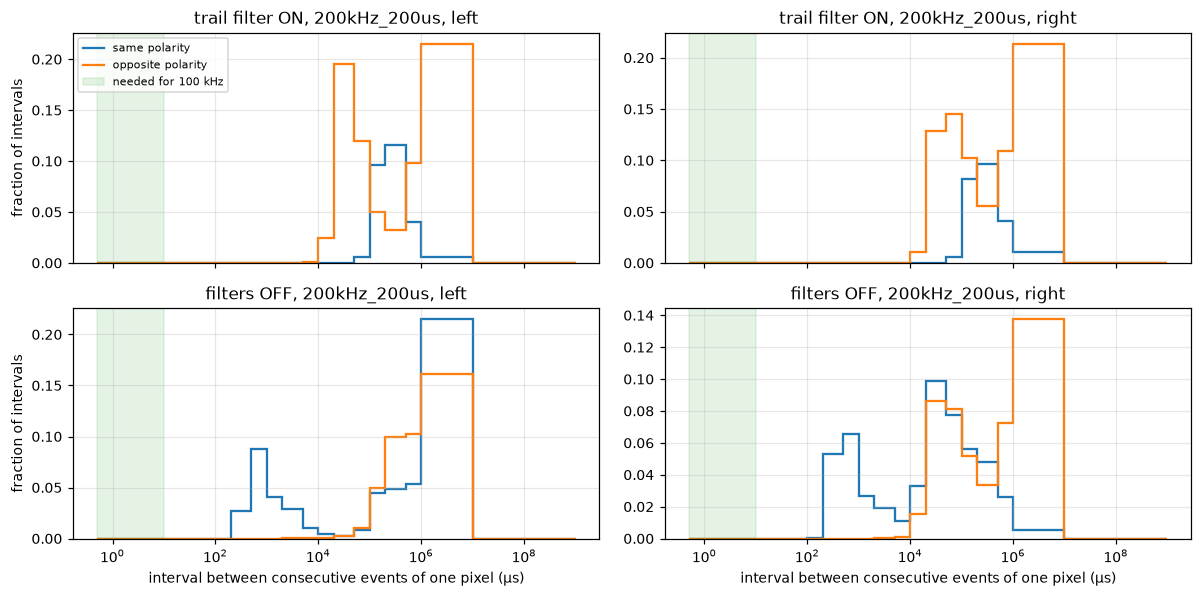

| Combination | Camera | 0.1 % quantile (µs) | 1 % quantile (µs) | Implied max rate (kev/s per pixel) |
|---|---|---|---|---|
| 100kHz_10us | left | 2546 | 10323 | 0.4 |
| 100kHz_10us | right | 106 | 1367 | 9.4 |
| 100kHz_50us | left | 277 | 407 | 3.6 |
| 100kHz_50us | right | 309 | 883 | 3.2 |
| 100kHz_100us | left | 271 | 362 | 3.7 |
| 100kHz_100us | right | 237 | 317 | 4.2 |
| 100kHz_200us | left | 306 | 396 | 3.3 |
| 100kHz_200us | right | 235 | 304 | 4.3 |
| 200kHz_10us | left | 4949 | 16665 | 0.2 |
| 200kHz_10us | right | 129 | 1124 | 7.8 |
| 200kHz_50us | left | 277 | 392 | 3.6 |
| 200kHz_50us | right | 291 | 666 | 3.4 |
| 200kHz_100us | left | 277 | 376 | 3.6 |
| 200kHz_100us | right | 228 | 301 | 4.4 |
| 200kHz_200us | left | 304 | 386 | 3.3 |
| 200kHz_200us | right | 228 | 294 | 4.4 |

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True)
for i, folder in enumerate((TRAIL, OFF)):
    for j, role in enumerate(("left", "right")):
        ax = axes[i, j]
        h = get(folder, 200e3, 200, role)["isi"]
        e = h["edges"].astype(float).copy(); e[0] = 0.5
        tot = h["same"].sum() + h["opposite"].sum()
        ax.stairs(h["same"] / tot, e, label="same polarity", lw=1.5)
        ax.stairs(h["opposite"] / tot, e, label="opposite polarity", lw=1.5)
        ax.axvspan(0.5, 10, color="tab:green", alpha=0.12, label="needed for 100 kHz")
        ax.set_xscale("log"); ax.set_title(f"{folder}, 200kHz_200us, {role}")
        if i == 1:
            ax.set_xlabel("interval between consecutive events of one pixel (µs)")
        if j == 0:
            ax.set_ylabel("fraction of intervals")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for r in recs:
    if r.folder != OFF:
        continue
    h = results[r]["isi"]
    rows.append([r.name, r.role, f"{h['same_q001']:.0f}", f"{h['same_q01']:.0f}", f"{1e3 / h['same_q001']:.1f}"])
md_table(["Combination", "Camera", "0.1 % quantile (µs)", "1 % quantile (µs)", "Implied max rate (kev/s per pixel)"],
         rows)

* **Trail filter ON**: same-polarity repeats closer than about 50–100 ms are removed, so each pixel reports little
  more than one ON and one OFF event per laser passage. These recordings cannot show fast per-pixel activity.
* **Filters OFF**: same-polarity repeats appear, but only 0.1 % of them are shorter than about **230–310 µs**,
  and nothing appears below 100 µs apart from residual noisy pixels. This floor is the pixel's refractory period
  plus its response time with the current biases. It caps one pixel at a few thousand events per second, while
  100–200 kHz would need 100–200 k events/s.

**A single pixel cannot follow the carrier.** It cannot even emit one event per carrier cycle.

## 5. Positive control: event timing locked to the motor steps

Events from each sweep are folded at that sweep's step frequency and aligned on the ON events' phase. The profile
shows when, within one step period, the pixels respond. A sharp peak would mean precise timing; a broad bump means
the response is smeared over tens of µs.

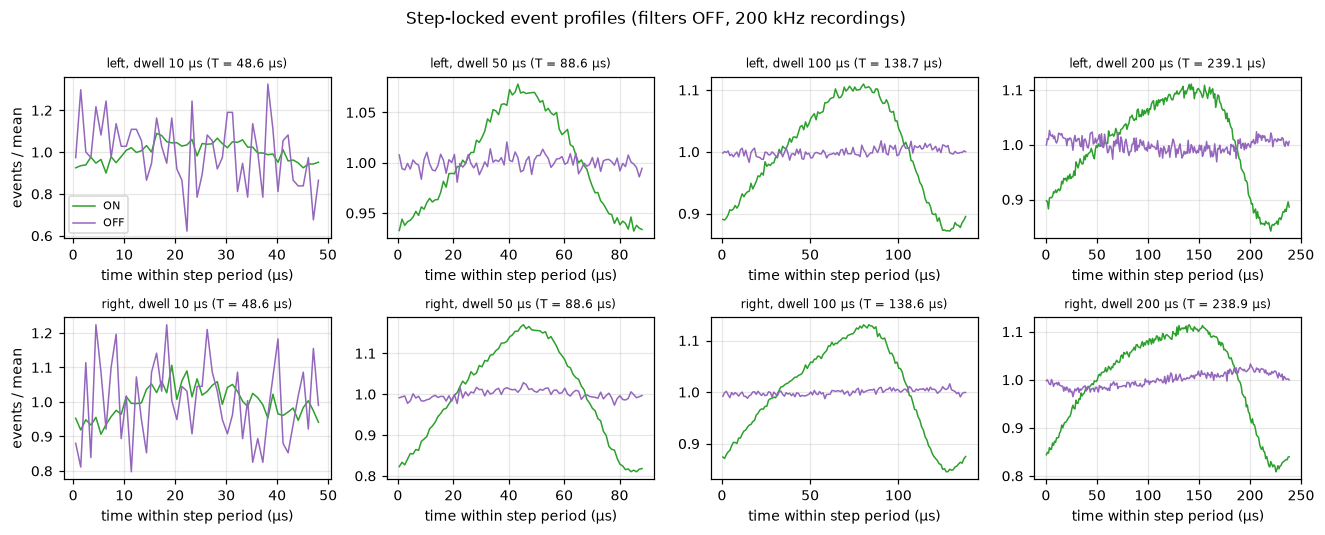

In [7]:
fig, axes = plt.subplots(2, len(DWELLS), figsize=(12, 4.8))
for j, dwell in enumerate(DWELLS):
    for i, role in enumerate(("left", "right")):
        ax = axes[i, j]
        res = get(OFF, 200e3, dwell, role)
        T = res["step_period_us"]
        for key, c, lab in (("fold_on", "tab:green", "ON"), ("fold_off", "tab:purple", "OFF")):
            h = res[key].astype(float)
            x = (np.arange(len(h)) + 0.5) / len(h) * T
            ax.plot(x, h / h.mean(), color=c, lw=1, label=lab)
        ax.set_title(f"{role}, dwell {dwell} µs (T = {T:.1f} µs)", fontsize=8)
        ax.set_xlabel("time within step period (µs)")
        if j == 0:
            ax.set_ylabel("events / mean")
axes[0, 0].legend(fontsize=7)
plt.suptitle("Step-locked event profiles (filters OFF, 200 kHz recordings)", y=1.0)
plt.tight_layout(); plt.show()

The step cadence is clearly present for dwell ≥ 50 µs, but only as a shallow, smooth modulation of the event rate
(peak/mean ≈ 1.07–1.17, trough ≈ 0.82–0.94). At 10 µs dwell it is buried in noise. ON events (laser arriving at a pixel) carry the timing; OFF events (laser leaving) are almost flat
because the pixel's decay is slow. So even a full step, a large and abrupt change of light, produces events spread
over most of the step period.

## 6. Temporal transfer: up to which frequency do event timestamps carry phase?

The step train is periodic, so phase locking can be tested at every harmonic k·f_step. Significance is the
−log10 p of the sweep-summed normalised power under the Gamma(S, 1) noise model; the dashed line marks p = 1e-4.

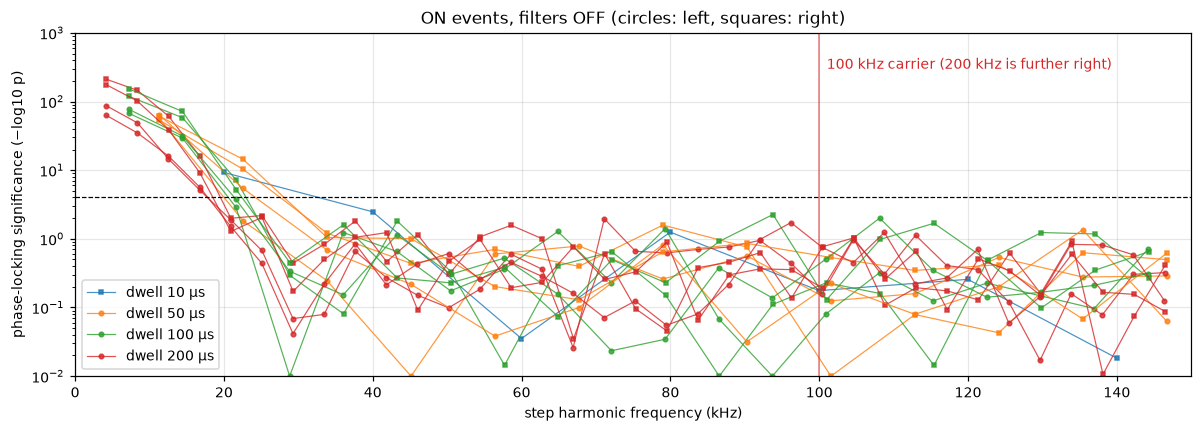

| Folder | Combination | Camera | Step locked | Highest locked harmonic (kHz) | Timing spread σ (µs) | Expected locking at f_mod (relative to f_step) |
|---|---|---|---|---|---|---|
| trail filter ON | 100kHz_10us | left | yes | 20.0 | 6.1 | 1e-3 |
| trail filter ON | 100kHz_10us | right | yes | 20.0 | 7.9 | 1e-5 |
| trail filter ON | 100kHz_50us | left | yes | 11.3 | 13.1 | 1e-14 |
| trail filter ON | 100kHz_50us | right | yes | 22.6 | 9.9 | 1e-8 |
| trail filter ON | 100kHz_100us | left | yes | 14.4 | 14.1 | 1e-17 |
| trail filter ON | 100kHz_100us | right | yes | 21.6 | 10.7 | 1e-10 |
| trail filter ON | 100kHz_200us | left | yes | 8.4 | 21.3 | 1e-39 |
| trail filter ON | 100kHz_200us | right | yes | 12.6 | 19.1 | 1e-31 |
| trail filter ON | 200kHz_10us | left | no | – | – | – |
| trail filter ON | 200kHz_10us | right | no | – | – | – |
| trail filter ON | 200kHz_50us | left | yes | 11.3 | 12.6 | 1e-54 |
| trail filter ON | 200kHz_50us | right | yes | 22.6 | 9.1 | 1e-29 |
| trail filter ON | 200kHz_100us | left | yes | 14.4 | 13.0 | 1e-57 |
| trail filter ON | 200kHz_100us | right | yes | 21.6 | 12.2 | 1e-51 |
| trail filter ON | 200kHz_200us | left | yes | 8.4 | 22.6 | 1e-175 |
| trail filter ON | 200kHz_200us | right | yes | 12.6 | 18.4 | 1e-116 |
| filters OFF | 100kHz_10us | left | no | – | – | – |
| filters OFF | 100kHz_10us | right | yes | 20.0 | 5.0 | 1e-2 |
| filters OFF | 100kHz_50us | left | yes | 11.3 | 14.0 | 1e-17 |
| filters OFF | 100kHz_50us | right | yes | 22.6 | 9.9 | 1e-8 |
| filters OFF | 100kHz_100us | left | yes | 14.4 | 10.9 | 1e-10 |
| filters OFF | 100kHz_100us | right | yes | 21.6 | 10.5 | 1e-9 |
| filters OFF | 100kHz_200us | left | yes | 16.7 | 15.6 | 1e-21 |
| filters OFF | 100kHz_200us | right | yes | 16.7 | 13.1 | 1e-15 |
| filters OFF | 200kHz_10us | left | no | – | – | – |
| filters OFF | 200kHz_10us | right | no | – | – | – |
| filters OFF | 200kHz_50us | left | yes | 22.6 | 12.1 | 1e-50 |
| filters OFF | 200kHz_50us | right | yes | 22.6 | 9.3 | 1e-30 |
| filters OFF | 200kHz_100us | left | yes | 14.4 | 11.2 | 1e-43 |
| filters OFF | 200kHz_100us | right | yes | 21.6 | 10.8 | 1e-40 |
| filters OFF | 200kHz_200us | left | yes | 16.7 | 15.7 | 1e-85 |
| filters OFF | 200kHz_200us | right | yes | 16.7 | 15.9 | 1e-87 |

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
seen = set()
for r in recs:
    res = results[r]
    if r.folder != OFF or not res.get("step_detected"):
        continue
    sig = np.clip(-res["harm_on_lp"], 0.01, None)
    ax.plot(res["harm_f"] / 1e3, sig, marker="o" if r.role == "left" else "s", ms=3, lw=0.8,
            color=DWELL_COLORS[r.dwell_us], alpha=0.8,
            label=f"dwell {r.dwell_us} µs" if r.dwell_us not in seen else None)
    seen.add(r.dwell_us)
ax.axhline(4, color="k", ls="--", lw=0.8)
ax.axvline(100, color="tab:red", lw=1, alpha=0.6)
ax.text(101, 300, "100 kHz carrier (200 kHz is further right)", color="tab:red")
ax.set_yscale("log"); ax.set_xlim(0, 150); ax.set_ylim(0.01, 1e3)
ax.set_xlabel("step harmonic frequency (kHz)"); ax.set_ylabel("phase-locking significance (−log10 p)")
ax.set_title("ON events, filters OFF (circles: left, squares: right)")
ax.legend(); plt.tight_layout(); plt.show()

rows = []
for r in recs:
    res = results[r]
    if not res.get("step_detected"):
        rows.append([r.folder, r.name, r.role, "no", "–", "–", "–"]); continue
    sig_us = res["timing_spread_us"]
    fs = float(np.mean(res["f_step"]))
    if np.isfinite(sig_us):
        # Relative phase-locking amplitude at f_mod vs at f_step for the same Gaussian timing spread
        lg = -2 * np.pi ** 2 * (sig_us * 1e-6) ** 2 * (r.fmod_hz ** 2 - fs ** 2) / np.log(10)
        pred = f"1e{lg:.0f}"
    else:
        pred = "–"
    rows.append([r.folder, r.name, r.role, "yes", f"{ma.bandwidth_khz(res):.1f}",
                 f"{sig_us:.1f}" if np.isfinite(sig_us) else "–", pred])
md_table(["Folder", "Combination", "Camera", "Step locked", "Highest locked harmonic (kHz)",
          "Timing spread σ (µs)", "Expected locking at f_mod (relative to f_step)"], rows)

Phase locking falls by roughly an order of magnitude per step harmonic and reaches the noise floor at about
**10–25 kHz** in every recording. For the 10 µs dwell, the fundamental at about 20 kHz is the only harmonic below
40 kHz, so its limit lies between 20 and 40 kHz.

The Gaussian-equivalent timing spread (from the drop between the 1st and 2nd harmonic) is σ ≈ 5–20 µs. It
includes pixel latency jitter, the response shape and any motor timing jitter, so the pixel alone may be somewhat
better. Even so, with σ ≈ 5 µs the expected locking at 100 kHz is ~10⁻² of that at the step fundamental, and
10⁻⁹ or less at 200 kHz. The event timestamps are 4–10× too blurred to carry the carrier's phase.

## 7. Direct search for the carrier

Normalised power summed over sweeps, divided by S (noise mean = 1), in a ±2 kHz window around the nominal
frequency. The dashed line is the level a peak must exceed for a global false-alarm probability of 1e-3 within
the window.

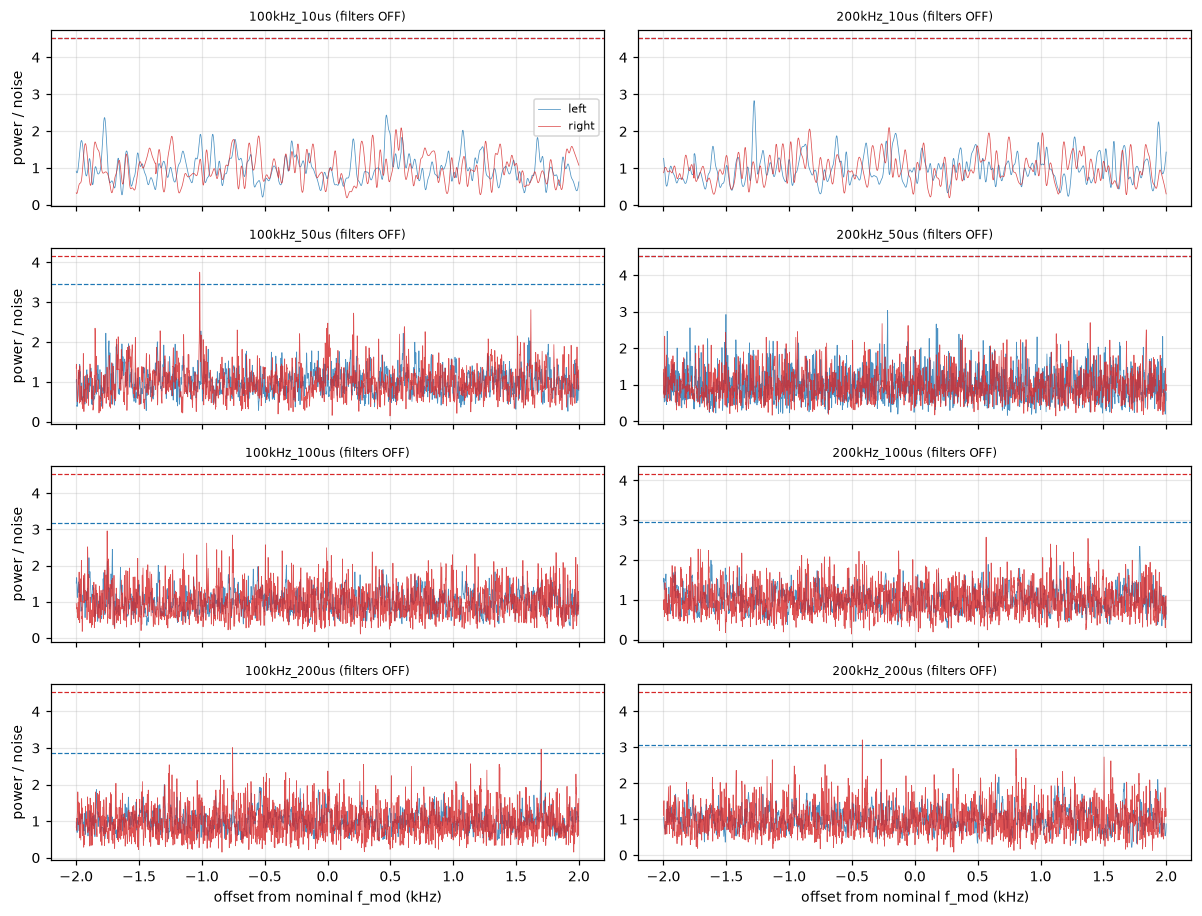

| Folder | Combination | Camera | Peak in window (kHz) | Peak / threshold (×noise) | p (all) | p (ON) | p (OFF) | p at 300 kHz | Detected (p < 1e-3) |
|---|---|---|---|---|---|---|---|---|---|
| trail filter ON | 100kHz_10us | left | 99.648 | 2.36 / 5.03 | 1 | 1 | 1 | 1 | no |
| trail filter ON | 100kHz_10us | right | 101.405 | 2.89 / 5.03 | 1 | 1 | 1 | 1 | no |
| trail filter ON | 100kHz_50us | left | 101.376 | 2.39 / 3.18 | 1e-0.2 | 1 | 1 | 1 | no |
| trail filter ON | 100kHz_50us | right | 101.068 | 2.21 / 3.18 | 1 | 1e-0.3 | 1 | 1 | no |
| trail filter ON | 100kHz_100us | left | 98.038 | 2.96 / 4.53 | 1 | 1 | 1e-0.6 | 1e-0.7 | no |
| trail filter ON | 100kHz_100us | right | 101.840 | 3.74 / 4.53 | 1e-1.4 | 1e-0.3 | 1e-0.5 | 1 | no |
| trail filter ON | 100kHz_200us | left | 99.428 | 2.55 / 3.65 | 1 | 1e-0.2 | 1 | 1 | no |
| trail filter ON | 100kHz_200us | right | 100.410 | 3.09 / 4.53 | 1 | 1 | 1e-0.2 | 1e-1.6 | no |
| trail filter ON | 200kHz_10us | left | 198.447 | 2.36 / 5.03 | 1 | 1 | 1 | – | no |
| trail filter ON | 200kHz_10us | right | 201.042 | 2.74 / 5.03 | 1 | 1 | 1 | – | no |
| trail filter ON | 200kHz_50us | left | 198.797 | 2.27 / 3.65 | 1 | 1e-2.6 | 1e-0.1 | – | no |
| trail filter ON | 200kHz_50us | right | 200.372 | 2.98 / 4.16 | 1e-0.2 | 1 | 1 | – | no |
| trail filter ON | 200kHz_100us | left | 198.079 | 3.22 / 4.53 | 1e-0.3 | 1 | 1 | – | no |
| trail filter ON | 200kHz_100us | right | 201.757 | 3.43 / 4.53 | 1e-0.7 | 1 | 1e-0.2 | – | no |
| trail filter ON | 200kHz_200us | left | 201.118 | 2.67 / 3.31 | 1e-0.8 | 1 | 1 | – | no |
| trail filter ON | 200kHz_200us | right | 198.361 | 2.67 / 3.88 | 1 | 1 | 1e-0.5 | – | no |
| filters OFF | 100kHz_10us | left | 100.469 | 2.43 / 4.53 | 1 | 1 | 1 | 1 | no |
| filters OFF | 100kHz_10us | right | 100.586 | 2.09 / 4.53 | 1 | 1 | 1 | 1 | no |
| filters OFF | 100kHz_50us | left | 98.992 | 2.28 / 3.46 | 1 | 1e-0.4 | 1 | 1 | no |
| filters OFF | 100kHz_50us | right | 98.983 | 3.75 / 4.16 | 1e-2.0 | 1 | 1e-0.2 | 1 | no |
| filters OFF | 100kHz_100us | left | 98.288 | 2.45 / 3.18 | 1e-0.4 | 1 | 1e-0.2 | 1 | no |
| filters OFF | 100kHz_100us | right | 98.247 | 2.96 / 4.53 | 1 | 1e-2.6 | 1 | 1e-0.2 | no |
| filters OFF | 100kHz_200us | left | 101.694 | 2.11 / 2.88 | 1 | 1 | 1 | 1 | no |
| filters OFF | 100kHz_200us | right | 99.244 | 3.01 / 4.53 | 1 | 1e-0.9 | 1 | 1 | no |
| filters OFF | 200kHz_10us | left | 198.721 | 2.83 / 4.53 | 1 | 1 | 1 | – | no |
| filters OFF | 200kHz_10us | right | 199.795 | 2.10 / 4.53 | 1 | 1 | 1 | – | no |
| filters OFF | 200kHz_50us | left | 199.783 | 3.04 / 4.53 | 1 | 1 | 1 | – | no |
| filters OFF | 200kHz_50us | right | 201.395 | 2.70 / 4.53 | 1 | 1 | 1 | – | no |
| filters OFF | 200kHz_100us | left | 201.790 | 2.35 / 2.96 | 1e-0.5 | 1 | 1 | – | no |
| filters OFF | 200kHz_100us | right | 200.567 | 2.57 / 4.16 | 1 | 1 | 1 | – | no |
| filters OFF | 200kHz_200us | left | 200.668 | 2.17 / 3.06 | 1 | 1 | 1e-2.5 | – | no |
| filters OFF | 200kHz_200us | right | 199.582 | 3.20 / 4.53 | 1e-0.3 | 1e-0.4 | 1e-0.2 | – | no |

In [9]:
fig, axes = plt.subplots(len(DWELLS), len(FREQS), figsize=(11, 2.1 * len(DWELLS)), sharex="col")
for i, dwell in enumerate(DWELLS):
    for j, fmod in enumerate(FREQS):
        ax = axes[i, j]
        for role in ("left", "right"):
            s = get(OFF, fmod, dwell, role)["search"][(fmod, "all")]
            ax.plot((s["window_f"] - fmod) / 1e3, s["window_p"] / s["S"], lw=0.5, color=CAM_COLORS[role],
                    alpha=0.8, label=role)
            ax.axhline(s["threshold"] / s["S"], color=CAM_COLORS[role], ls="--", lw=0.8)
        ax.set_title(f"{fmod / 1e3:.0f}kHz_{dwell}us (filters OFF)", fontsize=8)
        if j == 0:
            ax.set_ylabel("power / noise")
        if i == len(DWELLS) - 1:
            ax.set_xlabel("offset from nominal f_mod (kHz)")
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

rows = []
for r in recs:
    sr = results[r]["search"]
    a, on, off = sr[(r.fmod_hz, "all")], sr[(r.fmod_hz, "on")], sr[(r.fmod_hz, "off")]
    row = [r.folder, r.name, r.role, f"{a['f_peak'] / 1e3:.3f}", f"{a['excess']:.2f} / {a['threshold'] / a['S']:.2f}",
           fmt_p(a["log10_p"]), fmt_p(on["log10_p"]), fmt_p(off["log10_p"])]
    if r.fmod_hz == 100e3:  # Odd harmonic of a 50 % square wave
        row.append(fmt_p(sr[(300e3, "all")]["log10_p"]))
    else:
        row.append("–")
    row.append("**YES**" if any(sr[(r.fmod_hz, k)]["detected"] for k in ("all", "on", "off")) else "no")
    rows.append(row)
md_table(["Folder", "Combination", "Camera", "Peak in window (kHz)", "Peak / threshold (×noise)", "p (all)",
          "p (ON)", "p (OFF)", "p at 300 kHz", "Detected (p < 1e-3)"], rows)

### Wide-band check (any frequency up to the 500 kHz Nyquist limit)

This covers a carrier that is off-nominal, aliased or harmonic. For each ~1 kHz block, the plot shows the
significance of its largest bin. With ~500 blocks, the dashed line is the 1e-3 global level.

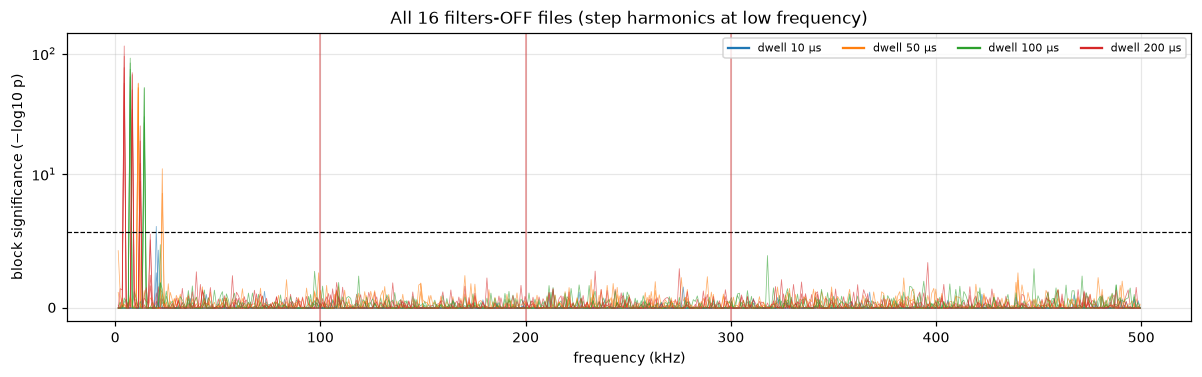

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for r in recs:
    if r.folder != OFF:
        continue
    fc, sig = results[r]["wideband"]
    ax.plot(fc / 1e3, sig, lw=0.5, color=DWELL_COLORS[r.dwell_us], alpha=0.6)
n_blocks = len(fc)
ax.axhline(-np.log10(ma.P_DETECT / n_blocks), color="k", ls="--", lw=0.8)
for f in (100, 200, 300):
    ax.axvline(f, color="tab:red", lw=1, alpha=0.5)
for d, c in DWELL_COLORS.items():
    ax.plot([], [], color=c, label=f"dwell {d} µs")
ax.set_yscale("symlog", linthresh=10); ax.set_xlabel("frequency (kHz)")
ax.set_ylabel("block significance (−log10 p)"); ax.set_title("All 16 filters-OFF files (step harmonics at low frequency)")
ax.legend(fontsize=7, ncol=4); plt.tight_layout(); plt.show()

**No recording, camera, polarity or folder shows the carrier**, neither at 100/200 kHz (± 2 kHz) nor at 300 kHz,
nor anywhere else above the step harmonics. The largest peaks are those expected from noise. The few p ≈ 0.003–0.01
entries are consistent with chance across the 288 tests in the table; the threshold is p < 1e-3.

## 8. Sensitivity: how many locked events would we have seen?

A random fraction of the sweep events is moved into the ON half of a carrier cycle at f_mod (1 µs timestamp
quantisation kept), simulating events perfectly phase-locked to the modulation. The same detector is then run.

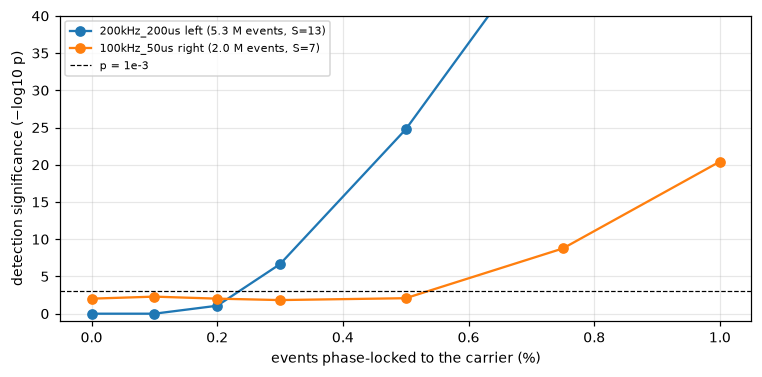

| Case | Smallest detected locked fraction |
|---|---|
| 200kHz_200us left | 0.30 % |
| 100kHz_50us right | 0.75 % |

In [11]:
INJ_CACHE = ma.CACHE_DIR / "injection.pkl"
FRACTIONS = [0.0, 0.001, 0.002, 0.003, 0.005, 0.0075, 0.01]
CASES = [(OFF, 200e3, 200, "left"), (OFF, 100e3, 50, "right")]
inj = pickle.load(open(INJ_CACHE, "rb")) if USE_CACHE and INJ_CACHE.exists() else {}
rng = np.random.default_rng(1)
for case in CASES:
    if case in inj:
        continue
    folder, fmod, dwell, role = case
    rec = next(r for r in recs if (r.folder, r.fmod_hz, r.dwell_us, r.role) == case)
    ev = ma.load_events(rec.path)
    ev = ma.remove_pixels(ev, ma.hot_pixels(ev)[0])
    sweeps = results[rec]["sweeps"]
    out = []
    for frac in FRACTIONS:
        t2 = ma.inject_locked(ev.t, frac, fmod, rng)
        s = ma.window_search(ma.sweep_spectra(t2, ev.p, sweeps, dwell), fmod)
        out.append((frac, s["log10_p"], s["f_peak"]))
    inj[case] = dict(n_sweep_events=results[rec]["n_sweep_events"]["all"], S=results[rec]["S"], out=out)
    del ev
pickle.dump(inj, open(INJ_CACHE, "wb"))

fig, ax = plt.subplots(figsize=(7, 3.5))
for case, d in inj.items():
    fr = [o[0] * 100 for o in d["out"]]; sig = [-o[1] for o in d["out"]]
    ax.plot(fr, sig, "o-", label=f"{case[1] / 1e3:.0f}kHz_{case[2]}us {case[3]} ({d['n_sweep_events'] / 1e6:.1f} M events, "
                                 f"S={d['S']})")
ax.axhline(3, color="k", ls="--", lw=0.8, label="p = 1e-3")
ax.set_ylim(-1, 40); ax.set_xlabel("events phase-locked to the carrier (%)")
ax.set_ylabel("detection significance (−log10 p)"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
md_table(["Case", "Smallest detected locked fraction"],
         [[f"{c[1] / 1e3:.0f}kHz_{c[2]}us {c[3]}",
           next((f"{o[0] * 100:.2f} %" for o in d["out"] if o[1] < np.log10(ma.P_DETECT)), "> 1 %")]
          for c, d in inj.items()])

If as few as **~0.3–1 % of the sweep events** were phase-locked to the carrier (depending on how many events a
recording has), the search would have found it. The 1 µs timestamps are not the limit. The analysis would have seen the carrier; the sensor
timing just does not contain it.

## 9. Conclusions

**1. The 100/200 kHz modulation is not detectable with the EVK4.** This holds for every frequency, dwell, camera
and polarity, with or without the trail filter, and with a test that would catch ~0.3–1 % phase-locked events.

**2. Why** (both limits are far from the carrier):
* *Per pixel*: same-polarity events of one pixel are ≥ ~230–310 µs apart (refractory period plus response time with
  the current biases), i.e. a few thousand events per second at most. A carrier needs ≥ 100 k/s.
* *Timing*: even the abrupt motor steps lock the event timestamps only up to ~10–25 kHz (Gaussian-equivalent
  spread σ ≈ 5–20 µs). The pixel front end effectively averages the 5–10 µs carrier cycles, so the laser looks like
  constant light at half power.

Bias tuning (shorter refractory period, faster low-pass filter, i.e. `bias_refr`, `bias_fo`) might gain a factor
of a few. That is still unlikely to bridge the 5–20× gap to 100–200 kHz; this is untested.

**3. What the cameras do see**:
* The **motor steps**: the real step period is **dwell + ~39 µs** (48.6/50.0, 88.6, 138.6, 238.9 µs). The step
  cadence is detectable for dwell ≥ 50 µs, mainly in **ON** events; OFF events, from the laser leaving a pixel, are
  slow and carry almost no timing.
* With a 10 µs dwell, only ~20–25 events per step per camera, and the step is barely detectable.

**4. Data quality issues found**
* **Right camera noise = 2 hot pixels** at (407, 685) and (763, 371), about 4.1 Mev/s each, OFF only; a third pixel
  (48, 212) is occasional. Masking them in hardware (IMX636 digital event mask, Metavision `I_DigitalEventMask`)
  should drop the right camera's background from ~9.1 to ~0.1–0.2 Mev/s, without the trail filter's loss of
  repeated events.
* **The left camera loses ~87 ms blocks of data** whenever its rate passes ~15 Mev/s with filters off, while the
  right camera handles ~30 Mev/s. Suspects are the left camera's USB port/cable/controller or its master role. Swap
  the ports, or swap master and slave, to tell them apart. Until then, an ERC limit just below 15 Mev/s on the left
  camera avoids the blackouts, at the cost of uniformly thinned events. It must be fixed before depth recordings.

**5. Implications for the depth scanner (≥ 10 fps)**
* A carrier cannot tag laser events. Laser events have to be identified some other way:
  * by their spatio-temporal structure: a thin, bright line of near-simultaneous ON events that jumps one step at
    a time;
  * by the step clock, which is visible at 4–20 kHz;
  * best, by wiring the motor step / scan-start signal into the camera's trigger input, so each event window maps
    to a known laser angle.
* Any temporal code must sit at ≤ ~10 kHz, i.e. last ≥ 100 µs. That is longer than a short dwell, so a code can
  only span several steps, or the step itself acts as the code.
* Scan budget at 10 fps: 100 ms / (dwell + 39 µs) ≈ **2040 / 1130 / 720 / 420 line positions** for 10 / 50 / 100 /
  200 µs dwell. Longer dwells give more events per step: about 25 / 150–260 / 580 / 1100–1800.